# Clasificación de residuos: entrenamiento mejorado

Mismo dataset (Garbage Classification V2, 8 clases). **Ejecutar en Colab con GPU** (Entorno de ejecución → Cambiar tipo → GPU) y luego *Ejecutar todo*.

**Qué mejora frente al notebook original**

| Mejora | Por qué |
|---|---|
| Limpieza: archivos ilegibles y **duplicados exactos** (MD5) fuera | Evita imágenes repetidas en entrenamiento y prueba (fuga de datos) |
| Partición **70/15/15 estratificada** con prueba independiente | Estimación honesta; la prueba se usa una sola vez |
| Pipeline **tf.data** con caché (uint8) y prefetch | Las imágenes se decodifican una sola vez; épocas mucho más rápidas |
| Aumento de datos **dentro del modelo** (GPU) | Menos carga de CPU, mismo efecto regularizador |
| Preprocesamiento oficial **dentro del modelo** | La app envía píxeles 0-255 sin riesgo de escalar mal |
| Precisión mixta (float16) | Más rápido y menos memoria en GPU |
| Pesos de clase + **label smoothing** | Mejor equilibrio entre clases y menos sobreconfianza |
| Fine-tuning con **BatchNorm congelada** y tasa baja | Ajuste fino más estable |
| Se **elige el mejor** entre fase 1 y fase 2 por validación | El fine-tuning no siempre mejora |
| **Validación cruzada** de 5 pliegues barata (sobre características) | Media y desviación de las métricas |
| Evaluación final con **TTA** (imagen + espejo) | Pequeña ganancia de robustez |
| Guarda curvas, matriz de confusión y métricas en JSON/PNG | Para pegar directo en el informe |

Cambia `CONFIG["backbone"]` para comparar `mobilenetv2` (sistema), `efficientnetb3` o `efficientnetv2b0`.

In [1]:
import tensorflow as tf
print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU:", gpus if gpus else "NO HAY GPU: activa una en Entorno de ejecución")

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Datos: montar Drive y descomprimir

In [2]:
import os, shutil, zipfile
from google.colab import drive
drive.mount("/content/drive")

ZIP_DRIVE = "/content/drive/MyDrive/garbage-dataset.zip"   # ajusta si lo moviste
DATA_ROOT = "/content/garbage"
if not os.path.exists(DATA_ROOT):
    os.makedirs(DATA_ROOT)
    shutil.copy(ZIP_DRIVE, "/content/garbage-dataset.zip")
    with zipfile.ZipFile("/content/garbage-dataset.zip") as z:
        z.extractall(DATA_ROOT)

DATA_DIR = os.path.join(DATA_ROOT, "garbage-dataset")
if not os.path.isdir(DATA_DIR):
    DATA_DIR = DATA_ROOT
print(DATA_DIR, os.listdir(DATA_DIR))

Mounted at /content/drive
/content/garbage/garbage-dataset ['metal', 'cardboard', 'clothes', 'battery', 'glass', 'paper', 'shoes', 'biological', 'plastic', 'trash']


## 2. Configuración

In [3]:
CONFIG = dict(
    backbone="mobilenetv2",      # "mobilenetv2" | "efficientnetb3" | "efficientnetv2b0"
    img_size=224,
    batch=64,
    epochs_head=12,              # fase 1: base congelada
    epochs_ft=12,                # fase 2: fine-tuning
    lr_head=1e-3,
    lr_ft=2e-5,
    ft_layers=30,                # capas finales de la base que se descongelan
    dense=128, dropout1=0.3, dropout2=0.2,
    label_smoothing=0.1,
    cv_folds=5,                  # 0 para omitir la validación cruzada
    mixed_precision=True,
    seed=42,
    out_dir="/content/salida",
    drive_out="/content/drive/MyDrive/modelos_residuos/entrenamiento_mejorado",
)
CLASES = ["battery", "biological", "cardboard", "glass", "metal", "paper", "plastic", "trash"]

In [4]:
import glob, hashlib, json, time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.utils import class_weight
from tensorflow.keras import callbacks, layers, losses, models, optimizers

C = CONFIG
IMG = C["img_size"]
AUTOTUNE = tf.data.AUTOTUNE
OUT = C["out_dir"]
os.makedirs(OUT, exist_ok=True)
tf.keras.utils.set_random_seed(C["seed"])
if gpus and C["mixed_precision"]:
    tf.keras.mixed_precision.set_global_policy("mixed_float16")
print("Política de precisión:", tf.keras.mixed_precision.global_policy().name)

Política de precisión: mixed_float16


## 3. Limpieza y partición 70/15/15
Se descartan archivos que no se pueden leer y duplicados exactos (mismo contenido), y luego se parte de forma estratificada.

In [5]:
EXT = (".jpg", ".jpeg", ".png", ".bmp", ".gif")
rutas, y = [], []
ilegibles = duplicados = 0
vistos = set()
for i, c in enumerate(CLASES):
    for f in sorted(glob.glob(os.path.join(DATA_DIR, c, "*"))):
        if not f.lower().endswith(EXT):
            ilegibles += 1
            continue
        try:
            with Image.open(f) as im:
                im.verify()
            with open(f, "rb") as fh:
                h = hashlib.md5(fh.read()).hexdigest()
        except Exception:
            ilegibles += 1
            continue
        if h in vistos:
            duplicados += 1
            continue
        vistos.add(h)
        rutas.append(f)
        y.append(i)
rutas, y = np.array(rutas), np.array(y)
print(f"Imágenes válidas: {len(rutas)} | ilegibles/formato no soportado: {ilegibles} | duplicados exactos: {duplicados}")

r_tr, r_tmp, y_tr, y_tmp = train_test_split(rutas, y, test_size=0.30, stratify=y, random_state=C["seed"])
r_va, r_te, y_va, y_te = train_test_split(r_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=C["seed"])
for nombre, yy in (("entrenamiento", y_tr), ("validación", y_va), ("prueba", y_te)):
    print(nombre, len(yy), np.bincount(yy, minlength=len(CLASES)).tolist())
json.dump({"class_names": CLASES}, open(f"{OUT}/clases.json", "w"))
split_info = {"validas": int(len(rutas)), "ilegibles": int(ilegibles), "duplicados": int(duplicados),
              "train": int(len(y_tr)), "val": int(len(y_va)), "test": int(len(y_te))}

Imágenes válidas: 12458 | ilegibles/formato no soportado: 0 | duplicados exactos: 0
entrenamiento 8720 [661, 698, 1277, 2142, 714, 1176, 1389, 663]
validación 1869 [141, 150, 274, 459, 153, 252, 298, 142]
prueba 1869 [142, 149, 274, 460, 153, 252, 297, 142]


## 4. Pipeline tf.data (decodifica una vez, caché en memoria, prefetch)

In [6]:
def cargar(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, (IMG, IMG))
    return tf.cast(tf.round(img), tf.uint8), label        # uint8: la caché ocupa 4 veces menos


def dataset(paths, labels, train=False, cache=True, onehot=True):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(cargar, num_parallel_calls=AUTOTUNE)
    if cache:
        ds = ds.cache()
    if train:
        ds = ds.shuffle(2048, seed=C["seed"])
    n = len(CLASES)
    ds = ds.map(lambda x, l: (tf.cast(x, tf.float32), tf.one_hot(l, n) if onehot else l),
                num_parallel_calls=AUTOTUNE)
    return ds.batch(C["batch"]).prefetch(AUTOTUNE)


ds_tr = dataset(r_tr, y_tr, train=True)
ds_va = dataset(r_va, y_va)
ds_te = dataset(r_te, y_te)
pesos = dict(enumerate(class_weight.compute_class_weight("balanced", classes=np.arange(len(CLASES)), y=y_tr)))
print({CLASES[k]: round(float(v), 3) for k, v in pesos.items()})

{'battery': 1.649, 'biological': 1.562, 'cardboard': 0.854, 'glass': 0.509, 'metal': 1.527, 'paper': 0.927, 'plastic': 0.785, 'trash': 1.644}


## 5. Modelo

In [7]:
def get_backbone(nombre):
    s = (IMG, IMG, 3)
    if nombre == "mobilenetv2":
        return tf.keras.applications.MobileNetV2(include_top=False, weights="imagenet", input_shape=s), True
    if nombre == "efficientnetb3":
        return tf.keras.applications.EfficientNetB3(include_top=False, weights="imagenet", input_shape=s), False
    if nombre == "efficientnetv2b0":
        return tf.keras.applications.EfficientNetV2B0(include_top=False, weights="imagenet", input_shape=s), False
    raise ValueError(nombre)
# El segundo valor indica si hay que reescalar a [-1, 1] (MobileNetV2). Las EfficientNet ya normalizan por dentro (entrada 0-255).


def construir():
    base, reescalar = get_backbone(C["backbone"])
    base.trainable = False
    aug = tf.keras.Sequential([
        layers.RandomFlip("horizontal"), layers.RandomRotation(0.06), layers.RandomZoom(0.2),
        layers.RandomTranslation(0.1, 0.1), layers.RandomContrast(0.2),
        layers.RandomBrightness(0.2, value_range=(0, 255))], name="aumento")   # solo activo al entrenar
    inp = layers.Input((IMG, IMG, 3))
    x = aug(inp)
    if reescalar:
        x = layers.Rescaling(1 / 127.5, offset=-1)(x)            # preprocesamiento oficial de MobileNetV2
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(C["dropout1"])(x)
    x = layers.Dense(C["dense"], activation="relu")(x)
    x = layers.Dropout(C["dropout2"])(x)
    out = layers.Dense(len(CLASES), activation="softmax", dtype="float32")(x)
    return models.Model(inp, out, name=f"{C['backbone']}_residuos"), base


def compilar(m, lr):
    m.compile(optimizer=optimizers.Adam(lr),
              loss=losses.CategoricalCrossentropy(label_smoothing=C["label_smoothing"]),
              metrics=["accuracy"])


modelo, base = construir()
compilar(modelo, C["lr_head"])
modelo.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenetv2_residuos"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumento (Sequential)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,984 (9.24 MB)

 Trainable params: 165,000 (644.53 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 6. Validación cruzada barata (5 pliegues)
Se extraen **una sola vez** las características del backbone congelado (sin aumento) y se entrena solo la cabeza en cada pliegue.
Mide la estabilidad del enfoque de transfer learning; el modelo final (con aumento y fine-tuning) debería igualarlo o superarlo.

In [8]:
cv_res = None
if C["cv_folds"] and C["cv_folds"] > 1:
    base_cv, reesc = get_backbone(C["backbone"])
    base_cv.trainable = False
    inp = layers.Input((IMG, IMG, 3))
    x = layers.Rescaling(1 / 127.5, offset=-1)(inp) if reesc else inp
    extractor = models.Model(inp, layers.GlobalAveragePooling2D()(base_cv(x, training=False)))

    r_all = np.concatenate([r_tr, r_va]); y_all = np.concatenate([y_tr, y_va])
    X = extractor.predict(dataset(r_all, y_all, cache=False, onehot=False).map(lambda a, b: a), verbose=0)
    accs, f1s = [], []
    skf = StratifiedKFold(C["cv_folds"], shuffle=True, random_state=C["seed"])
    for k, (i_tr, i_va) in enumerate(skf.split(X, y_all), 1):
        cab = models.Sequential([layers.Input((X.shape[1],)), layers.Dropout(C["dropout1"]),
                                 layers.Dense(C["dense"], activation="relu"), layers.Dropout(C["dropout2"]),
                                 layers.Dense(len(CLASES), activation="softmax")])
        cab.compile(optimizer=optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        pw = dict(enumerate(class_weight.compute_class_weight("balanced", classes=np.arange(len(CLASES)), y=y_all[i_tr])))
        cab.fit(X[i_tr], y_all[i_tr], epochs=25, batch_size=128, verbose=0, class_weight=pw)
        p = cab.predict(X[i_va], verbose=0).argmax(1)
        accs.append(float((p == y_all[i_va]).mean())); f1s.append(float(f1_score(y_all[i_va], p, average="macro")))
        print(f"Pliegue {k}: accuracy {accs[-1]:.4f} | macro-F1 {f1s[-1]:.4f}")
    cv_res = {"accuracy_media": float(np.mean(accs)), "accuracy_desv": float(np.std(accs)),
              "macroF1_media": float(np.mean(f1s)), "macroF1_desv": float(np.std(f1s)), "pliegues": C["cv_folds"]}
    print(cv_res)
    json.dump(cv_res, open(f"{OUT}/validacion_cruzada.json", "w"), indent=2)
    del extractor, base_cv, X

Pliegue 1: accuracy 0.9320 | macro-F1 0.9308
Pliegue 2: accuracy 0.9301 | macro-F1 0.9274
Pliegue 3: accuracy 0.9207 | macro-F1 0.9232
Pliegue 4: accuracy 0.9240 | macro-F1 0.9235
Pliegue 5: accuracy 0.9206 | macro-F1 0.9189
{'accuracy_media': 0.9254882570744586, 'accuracy_desv': 0.004751668700660265, 'macroF1_media': 0.9247829988847611, 'macroF1_desv': 0.004051825208587447, 'pliegues': 5}


## 7. Entrenamiento fase 1: cabeza con la base congelada

In [9]:
t0 = time.time()
cb1 = [callbacks.ModelCheckpoint(f"{OUT}/mejor_fase1.keras", monitor="val_accuracy", save_best_only=True),
       callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
       callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6)]
h1 = modelo.fit(ds_tr, validation_data=ds_va, epochs=C["epochs_head"], callbacks=cb1, class_weight=pesos)

Epoch 1/12
137/137 ━━━━━━━━━━━━━━━━━━━━ 49s 223ms/step - accuracy: 0.7083 - loss: 1.1424 - val_accuracy: 0.8711 - val_loss: 0.8153 - learning_rate: 0.0010
Epoch 2/12
137/137 ━━━━━━━━━━━━━━━━━━━━ 17s 123ms/step - accuracy: 0.8131 - loss: 0.9065 - val_accuracy: 0.8759 - val_loss: 0.8025 - learning_rate: 0.0010
Epoch 3/12
137/137 ━━━━━━━━━━━━━━━━━━━━ 17s 125ms/step - accuracy: 0.8343 - loss: 0.8623 - val_accuracy: 0.8818 - val_loss: 0.7728 - learning_rate: 0.0010
Epoch 4/12
137/137 ━━━━━━━━━━━━━━━━━━━━ 17s 125ms/step - accuracy: 0.8524 - loss: 0.8293 - val_accuracy: 0.8876 - val_loss: 0.7677 - learning_rate: 0.0010
Epoch 5/12
137/137 ━━━━━━━━━━━━━━━━━━━━ 20s 123ms/step - accuracy: 0.8597 - loss: 0.8115 - val_accuracy: 0.8951 - val_loss: 0.7423 - learning_rate: 0.0010
Epoch 6/12
137/137 ━━━━━━━━━━━━━━━━━━━━ 16s 119ms/step - accuracy: 0.8703 - loss: 0.7956 - val_accuracy: 0.8909 - val_loss: 0.7437 - learning_rate: 0.0010
Epoch 7/12
137/137 ━━━━━━━━━━━━━━━━━━━━ 17s 121ms/step - accuracy: 0.8

## 8. Fase 2: fine-tuning (últimas capas, BatchNorm congelada, tasa baja)

In [10]:
base.trainable = True
for capa in base.layers[:-C["ft_layers"]]:
    capa.trainable = False
for capa in base.layers:
    if isinstance(capa, layers.BatchNormalization):
        capa.trainable = False
compilar(modelo, C["lr_ft"])          # recompilar tras cambiar trainable

ini = len(h1.history["loss"])
cb2 = [callbacks.ModelCheckpoint(f"{OUT}/mejor_final.keras", monitor="val_accuracy", save_best_only=True),
       callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
       callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7)]
h2 = modelo.fit(ds_tr, validation_data=ds_va, epochs=ini + C["epochs_ft"], initial_epoch=ini,
                callbacks=cb2, class_weight=pesos)
t_train = time.time() - t0
print(f"Tiempo total de entrenamiento: {t_train / 60:.1f} min")

Epoch 13/24
137/137 ━━━━━━━━━━━━━━━━━━━━ 33s 155ms/step - accuracy: 0.9018 - loss: 0.7255 - val_accuracy: 0.9112 - val_loss: 0.7034 - learning_rate: 2.0000e-05
Epoch 14/24
137/137 ━━━━━━━━━━━━━━━━━━━━ 18s 129ms/step - accuracy: 0.9089 - loss: 0.7099 - val_accuracy: 0.9064 - val_loss: 0.7045 - learning_rate: 2.0000e-05
Epoch 15/24
137/137 ━━━━━━━━━━━━━━━━━━━━ 21s 151ms/step - accuracy: 0.9125 - loss: 0.6966 - val_accuracy: 0.9149 - val_loss: 0.6959 - learning_rate: 2.0000e-05
Epoch 16/24
137/137 ━━━━━━━━━━━━━━━━━━━━ 17s 127ms/step - accuracy: 0.9236 - loss: 0.6818 - val_accuracy: 0.9139 - val_loss: 0.6948 - learning_rate: 2.0000e-05
Epoch 17/24
137/137 ━━━━━━━━━━━━━━━━━━━━ 17s 127ms/step - accuracy: 0.9229 - loss: 0.6806 - val_accuracy: 0.9085 - val_loss: 0.6961 - learning_rate: 2.0000e-05
Epoch 18/24
137/137 ━━━━━━━━━━━━━━━━━━━━ 18s 131ms/step - accuracy: 0.9269 - loss: 0.6725 - val_accuracy: 0.9235 - val_loss: 0.6787 - learning_rate: 2.0000e-05
Epoch 19/24
137/137 ━━━━━━━━━━━━━━━━━━━━

## 9. Elegir el mejor modelo según validación (el fine-tuning no siempre mejora)

fase 1 (cabeza): val_accuracy 0.9090 | val_loss 0.7109
fase 2 (fine-tuning): val_accuracy 0.9267 | val_loss 0.6729
Modelo elegido: fase 2 (fine-tuning)


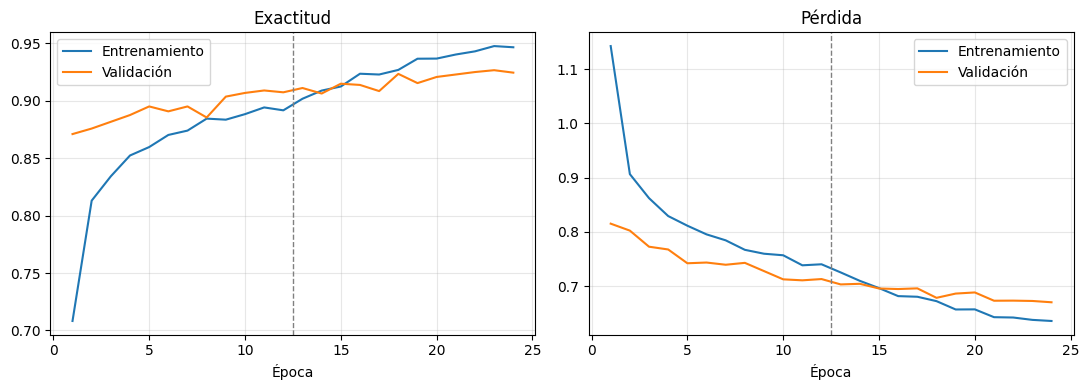

In [11]:
cands = {}
for nombre, ruta in (("fase 1 (cabeza)", f"{OUT}/mejor_fase1.keras"), ("fase 2 (fine-tuning)", f"{OUT}/mejor_final.keras")):
    if os.path.exists(ruta):
        m = tf.keras.models.load_model(ruta)
        loss, acc = m.evaluate(ds_va, verbose=0)
        cands[nombre] = (acc, loss, m)
        print(f"{nombre}: val_accuracy {acc:.4f} | val_loss {loss:.4f}")
elegido = max(cands, key=lambda k: cands[k][0])
mejor = cands[elegido][2]
print("Modelo elegido:", elegido)

# curvas de entrenamiento
hist = {k: h1.history[k] + h2.history[k] for k in ("accuracy", "val_accuracy", "loss", "val_loss")}
ep = np.arange(1, len(hist["loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (k1, k2, tt) in zip(ax, (("accuracy", "val_accuracy", "Exactitud"), ("loss", "val_loss", "Pérdida"))):
    a.plot(ep, hist[k1], label="Entrenamiento"); a.plot(ep, hist[k2], label="Validación")
    a.axvline(ini + 0.5, color="gray", ls="--", lw=1); a.set_title(tt); a.set_xlabel("Época"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT}/curvas_entrenamiento.png", dpi=200); plt.show()

## 10. Evaluación final (conjunto de prueba, una sola vez) con TTA

Accuracy en prueba: 0.9294 | con TTA: 0.9299
              precision    recall  f1-score   support

     battery      0.986     0.965     0.975       142
  biological      0.935     0.966     0.950       149
   cardboard      0.956     0.945     0.950       274
       glass      0.972     0.917     0.944       460
       metal      0.835     0.961     0.894       153
       paper      0.902     0.917     0.909       252
     plastic      0.922     0.912     0.917       297
       trash      0.876     0.894     0.885       142

    accuracy                          0.930      1869
   macro avg      0.923     0.935     0.928      1869
weighted avg      0.932     0.930     0.930      1869



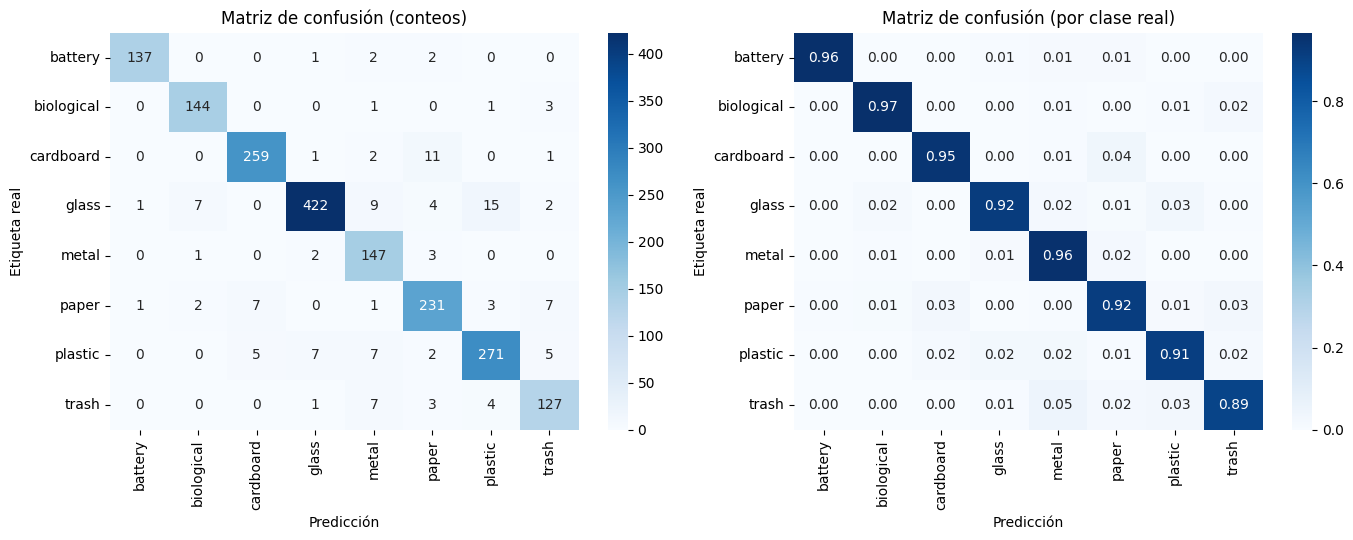

Latencia por imagen: 79 ms


In [12]:
imgs_te = ds_te.map(lambda x, l: x)
p = mejor.predict(imgs_te, verbose=0)
p_flip = mejor.predict(imgs_te.map(lambda x: tf.image.flip_left_right(x)), verbose=0)
ys = np.concatenate([l.numpy().argmax(1) for _, l in ds_te])
y_pred, y_tta = p.argmax(1), ((p + p_flip) / 2).argmax(1)
acc, acc_tta = float((y_pred == ys).mean()), float((y_tta == ys).mean())
print(f"Accuracy en prueba: {acc:.4f} | con TTA: {acc_tta:.4f}")

reporte = classification_report(ys, y_tta, target_names=CLASES, digits=3, output_dict=True)
print(classification_report(ys, y_tta, target_names=CLASES, digits=3))
cm = confusion_matrix(ys, y_tta)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASES, yticklabels=CLASES, ax=ax[0])
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASES, yticklabels=CLASES, ax=ax[1])
for a, tt in zip(ax, ("Matriz de confusión (conteos)", "Matriz de confusión (por clase real)")):
    a.set_title(tt); a.set_xlabel("Predicción"); a.set_ylabel("Etiqueta real")
plt.tight_layout(); plt.savefig(f"{OUT}/matriz_confusion.png", dpi=200); plt.show()

# latencia por imagen (1 imagen, este equipo)
uno = tf.zeros((1, IMG, IMG, 3))
for _ in range(3):
    mejor.predict(uno, verbose=0)
t = time.time()
for _ in range(20):
    mejor.predict(uno, verbose=0)
lat_ms = (time.time() - t) / 20 * 1000
print(f"Latencia por imagen: {lat_ms:.0f} ms")

## 11. Guardar y copiar a Drive

In [13]:
nombre_modelo = f"{C['backbone']}_mejorado.keras"
mejor.save(f"{OUT}/{nombre_modelo}")                       # entrada 0-255; el preprocesamiento va dentro

resumen = {
    "backbone": C["backbone"], "modelo_elegido": elegido, "configuracion": C, "particion": split_info,
    "val_accuracy_fase1": float(cands.get("fase 1 (cabeza)", (np.nan,))[0]),
    "val_accuracy_fase2": float(cands.get("fase 2 (fine-tuning)", (np.nan,))[0]),
    "test_accuracy": acc, "test_accuracy_tta": acc_tta,
    "test_macroF1_tta": float(f1_score(ys, y_tta, average="macro")),
    "test_F1_clase_mas_debil": float(min(reporte[c]["f1-score"] for c in CLASES)),
    "validacion_cruzada": cv_res, "latencia_ms": lat_ms, "minutos_entrenamiento": t_train / 60,
    "parametros": int(mejor.count_params()), "reporte": reporte,
}
json.dump(resumen, open(f"{OUT}/metricas_test.json", "w"), indent=2, ensure_ascii=False)

os.makedirs(C["drive_out"], exist_ok=True)
for f in os.listdir(OUT):
    if f.startswith("mejor_fase1") or f.startswith("mejor_final"):
        continue
    shutil.copy(os.path.join(OUT, f), C["drive_out"])
print("Guardado en Drive:", C["drive_out"], os.listdir(C["drive_out"]))

Guardado en Drive: /content/drive/MyDrive/modelos_residuos/entrenamiento_mejorado ['curvas_entrenamiento.png', 'validacion_cruzada.json', 'mobilenetv2_mejorado.keras', 'clases.json', 'matriz_confusion.png', 'metricas_test.json']


## 12. Resumen para el informe
Copia estos números a las tablas de desempeño, métricas por clase y KPI del informe (conjunto de **prueba**). Además,
sube `mobilenetv2_mejorado.keras` a la carpeta `models/` del repositorio.

In [14]:
print(f"Backbone: {C['backbone']} | modelo elegido: {elegido}")
print(f"Validación: fase 1 = {resumen['val_accuracy_fase1']:.4f} | fase 2 = {resumen['val_accuracy_fase2']:.4f}")
print(f"PRUEBA  accuracy = {acc:.4f} | con TTA = {acc_tta:.4f} | macro-F1 = {resumen['test_macroF1_tta']:.4f} | F1 mínimo por clase = {resumen['test_F1_clase_mas_debil']:.4f}")
if cv_res:
    print(f"CV {cv_res['pliegues']} pliegues: accuracy = {cv_res['accuracy_media']:.4f} ± {cv_res['accuracy_desv']:.4f} | macro-F1 = {cv_res['macroF1_media']:.4f} ± {cv_res['macroF1_desv']:.4f}")
print(f"Latencia: {lat_ms:.0f} ms/imagen | parámetros: {resumen['parametros']:,} | entrenamiento: {t_train / 60:.1f} min")

Backbone: mobilenetv2 | modelo elegido: fase 2 (fine-tuning)
Validación: fase 1 = 0.9090 | fase 2 = 0.9267
PRUEBA  accuracy = 0.9294 | con TTA = 0.9299 | macro-F1 = 0.9282 | F1 mínimo por clase = 0.8850
CV 5 pliegues: accuracy = 0.9255 ± 0.0048 | macro-F1 = 0.9248 ± 0.0041
Latencia: 79 ms/imagen | parámetros: 2,422,984 | entrenamiento: 7.8 min
